In [1]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.linalg import eigvalsh
from scipy.linalg import LinAlgError

In [2]:
# lattice defined like so:
a=1
a1 = a*np.array([np.sqrt(3)/2,-1/2])
a2 = a*np.array([np.sqrt(3)/2,1/2])

# The ribbon is sliced along [1,0] direction, N cells wide.
# breaking symmetry cells making "barber pole" stripes:

N = 6

# n. neighbor directions

def Nvlist(n=N):
    Nvlist_inner = np.array([a1,a2,a2-a1,-a1,-a2,a1-a2])
    Nvlist_bottom_edge_1 = np.array([a2,a2-a1,-a1])
    Nvlist_bottom_edge_2 = np.array([a1,a2,a2-a1,-a1,-a2])
    Nvlist_top_edge_1 = np.array([a1,a2,-a1,-a2,a1-a2])
    Nvlist_top_edge_2 = np.array([a1,-a2,a1-a2])

    Nvlist = [Nvlist_inner for _ in range(n)]
    Nvlist[0]=Nvlist_bottom_edge_1
    Nvlist[1]=Nvlist_bottom_edge_2
    Nvlist[-2]=Nvlist_top_edge_1
    Nvlist[-1]=Nvlist_top_edge_2
    return Nvlist

# n. neighbor indices

def offsetlist(n=N):
    offsets_inner = np.array([-1,1,2,1,-1,-2])
    offsets_bottom_1 = np.array([1,2,1])
    offsets_bottom_2 = np.array([-1,1,2,1,-1])
    offsets_top_1 = np.array([-1,1,1,-1,-2])
    offsets_top_2 = np.array([-1,-1,-2])

    offsetlist = [offsets_inner for _ in range(n)]
    offsetlist[0]=offsets_bottom_1
    offsetlist[1]=offsets_bottom_2
    offsetlist[-2] = offsets_top_1
    offsetlist[-1] = offsets_top_2
    return offsetlist

In [3]:
# Building the matrices

def T(k,n=N):
    R = [a2*i for i in range(n)]
    offsets = offsetlist(n)
    Nv = Nvlist(n)
    Tk = np.array([[0 for i in range(n)] for i in range(n)], dtype = complex)
    for i in range(n):
        Ri = R[i]
        offsetrow = offsets[i]
        Nvrow = Nv[i]
        for offset,dr in zip(offsetrow,Nvrow):
            Tk[i,i+offset] += -1*np.exp(1j*k@(dr))
    return Tk



In [4]:
# reciprocal lattice. only needs one value because
# there is only one infinite axis

b = np.pi/np.linalg.norm(a1+a2)

# kpoints

Z=500
Knames = [r'$-X$',r'$\Gamma$',r'$X$']
Xpath = np.linspace(-b,b,2*Z)
Kpath = np.array([[x,0] for x in Xpath])
Xpoints = [-b,0,b]

In [8]:
#Number of atoms going across the ribbon

N_odd = 7
N_even = N_odd+1

# Solving for E for the Odd N
Eodd = [[] for k in Kpath]
for i,k in enumerate(Kpath):
    try:
        Eodd[i] = eigvalsh(T(k,N_odd))
    except LinAlgError:
        Eodd[i] = [float('nan') for _ in range(N_odd)]
EoddT = np.transpose(Eodd)

# Even N
Eeven = [[] for k in Kpath]
for i,k in enumerate(Kpath):
    try:
        Eeven[i] = eigvalsh(T(k,N_even))
    except LinAlgError:
        Eeven[i] = [float('nan') for _ in range(N_even)]
EevenT = np.transpose(Eeven)

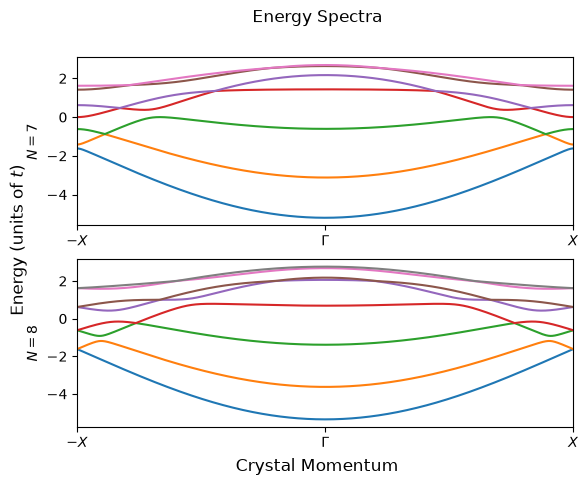

In [9]:
#Plotting

fig, (ax1,ax2) = plt.subplots(2)
for E in EoddT:
    ax1.plot(Xpath,E)

ax1.set_ylabel(f'$N={N_odd}$');
ax1.set_xlim(Xpoints[0],Xpoints[-1])
ax1.set_xticks(Xpoints,Knames);


for E in EevenT:
    ax2.plot(Xpath,E)
ax2.sharex(ax1)
ax2.set_ylabel(f'$N={N_even}$');

fig.suptitle('Energy Spectra');
fig.supylabel(r'Energy (units of $t$)');
fig.supxlabel('Crystal Momentum');